# Student dropout: flag at-risk students after the first semester

Data: *Predict Students' Dropout and Academic Success*, UCI repository (id 697), 4,424 students
from a Portuguese polytechnic, enrolled 2008-2019. Target: did the student drop out.

Only what is known at the end of the first semester is used. The second semester columns are
dropped on purpose: by then it is late to help.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, mutual_info_score, precision_recall_curve
import xgboost as xgb
import prep
pd.set_option('display.width', 160)

## Data preparation

In [2]:
raw = prep.clean_names(pd.read_csv('data/students.csv', sep=';'))
print(raw.shape)
raw.columns.tolist()

(4424, 37)


['marital_status',
 'application_mode',
 'application_order',
 'course',
 'daytime_evening_attendance',
 'previous_qualification',
 'previous_qualification_grade',
 'nacionality',
 'mothers_qualification',
 'fathers_qualification',
 'mothers_occupation',
 'fathers_occupation',
 'admission_grade',
 'displaced',
 'educational_special_needs',
 'debtor',
 'tuition_fees_up_to_date',
 'gender',
 'scholarship_holder',
 'age_at_enrollment',
 'international',
 'curricular_units_1st_sem_credited',
 'curricular_units_1st_sem_enrolled',
 'curricular_units_1st_sem_evaluations',
 'curricular_units_1st_sem_approved',
 'curricular_units_1st_sem_grade',
 'curricular_units_1st_sem_without_evaluations',
 'curricular_units_2nd_sem_credited',
 'curricular_units_2nd_sem_enrolled',
 'curricular_units_2nd_sem_evaluations',
 'curricular_units_2nd_sem_approved',
 'curricular_units_2nd_sem_grade',
 'curricular_units_2nd_sem_without_evaluations',
 'unemployment_rate',
 'inflation_rate',
 'gdp',
 'target']

In [3]:
raw.isna().sum().sum(), raw.duplicated().sum()

(np.int64(0), np.int64(0))

In [4]:
df = prep.load()
df[prep.NUMERICAL].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
application_order,4424.0,1.73,1.31,0.00,1.0,1.00,2.00,9.00
daytime_evening_attendance,4424.0,0.89,0.31,0.00,1.0,1.00,1.00,1.00
previous_qualification_grade,4424.0,132.61,13.19,95.00,125.0,133.10,140.00,190.00
admission_grade,4424.0,126.98,14.48,95.00,117.9,126.10,134.80,190.00
displaced,4424.0,0.55,0.50,0.00,0.0,1.00,1.00,1.00
educational_special_needs,4424.0,0.01,0.11,0.00,0.0,0.00,0.00,1.00
debtor,4424.0,0.11,0.32,0.00,0.0,0.00,0.00,1.00
tuition_fees_up_to_date,4424.0,0.88,0.32,0.00,1.0,1.00,1.00,1.00
gender,4424.0,0.35,0.48,0.00,0.0,0.00,1.00,1.00
scholarship_holder,4424.0,0.25,0.43,0.00,0.0,0.00,0.00,1.00


## EDA\n\n### Target

In [5]:
print(df.target.value_counts())
print('dropout rate:', round(df.dropout.mean(), 3))

target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
dropout rate: 0.321


32% dropped out. *Enrolled* (still studying when the data was collected, 18%) counts as
not dropped out here; some of them will still leave, which makes the problem a bit harder
than it looks.

### Dropout rate by group

In [6]:
def rate(col):
    g = df.groupby(col).dropout.agg(['mean', 'count']).sort_values('mean', ascending=False)
    g['risk_ratio'] = g['mean'] / df.dropout.mean()
    return g.round(3)

for c in ['debtor', 'tuition_fees_up_to_date', 'scholarship_holder', 'gender', 'displaced', 'daytime_evening_attendance']:
    display(rate(c))

,mean,count,risk_ratio
debtor,,,
1,0.620,503,1.931
0,0.283,3921,0.881


,mean,count,risk_ratio
tuition_fees_up_to_date,,,
0,0.866,528,2.695
1,0.247,3896,0.770


,mean,count,risk_ratio
scholarship_holder,,,
0,0.387,3325,1.205
1,0.122,1099,0.380


,mean,count,risk_ratio
gender,,,
1,0.451,1556,1.403
0,0.251,2868,0.782


,mean,count,risk_ratio
displaced,,,
0,0.376,1998,1.172
1,0.276,2426,0.859


,mean,count,risk_ratio
daytime_evening_attendance,,,
0,0.429,483,1.334
1,0.308,3941,0.959


In [7]:
rate('course')

,mean,count,risk_ratio
course,,,
biofuel_production,0.667,12,2.076
equinculture,0.553,141,1.722
informatics_engineering,0.541,170,1.685
management_evening,0.507,268,1.580
basic_education,0.443,192,1.378
agronomy,0.410,210,1.275
oral_hygiene,0.384,86,1.195
animation_multimedia,0.381,215,1.187
tourism,0.381,252,1.186


Students with tuition in arrears drop out 87% of the time, against 25% for those who are up
to date. Debtors 62% vs 28%. Scholarship holders 12% vs 39%. By course the spread is wide:
equinculture, informatics engineering and the evening management course are above 50%,
nursing is at 15%. Biofuel production shows 67%, but that is 8 out of 12 students.

### Mutual information with the target (categorical)

In [8]:
cat_mi = pd.Series({c: mutual_info_score(df[c], df.dropout) for c in prep.CATEGORICAL}).sort_values(ascending=False)
cat_mi.round(4)

application_mode          0.0444
course                    0.0346
mothers_occupation        0.0237
previous_qualification    0.0217
fathers_qualification     0.0203
fathers_occupation        0.0202
mothers_qualification     0.0201
marital_status            0.0064
nacionality               0.0026
dtype: float64

### Correlation with the target (numerical)

In [9]:
corr = df[prep.NUMERICAL].corrwith(df.dropout).sort_values()
corr.round(3)

approved_ratio_1st_sem                         -0.591
curricular_units_1st_sem_grade                 -0.481
curricular_units_1st_sem_approved              -0.479
tuition_fees_up_to_date                        -0.429
scholarship_holder                             -0.245
curricular_units_1st_sem_enrolled              -0.125
displaced                                      -0.107
admission_grade                                -0.096
curricular_units_1st_sem_evaluations           -0.090
daytime_evening_attendance                     -0.080
previous_qualification_grade                   -0.078
application_order                              -0.070
gdp                                            -0.046
curricular_units_1st_sem_credited              -0.029
evaluated_ratio_1st_sem                        -0.022
international                                  -0.010
educational_special_needs                       0.003
unemployment_rate                               0.013
inflation_rate              

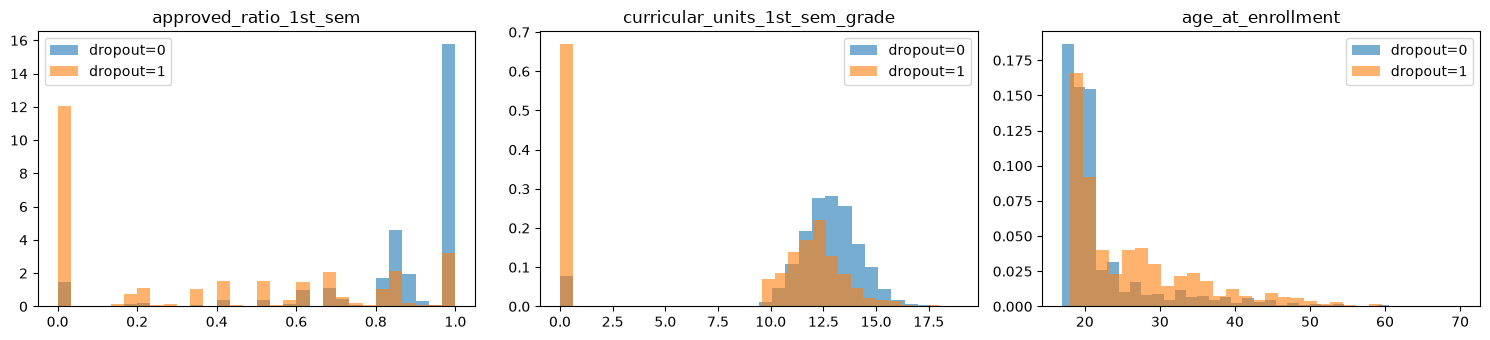

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, c in zip(ax, ['approved_ratio_1st_sem', 'curricular_units_1st_sem_grade', 'age_at_enrollment']):
    for t, g in df.groupby('dropout'):
        a.hist(g[c], bins=30, alpha=.6, label=f'dropout={t}', density=True)
    a.set_title(c); a.legend()
plt.tight_layout(); plt.show()

The first semester is the story. The share of enrolled units that were approved
(`approved_ratio_1st_sem`, built here) correlates -0.59 with dropout, more than any
original column. Age at enrollment goes the other way (0.25): older students drop out more.

## Validation framework\n\n60/20/20 split, stratified on the target.

In [11]:
full_train, test = train_test_split(df, test_size=0.2, random_state=1, stratify=df.dropout)
train, val = train_test_split(full_train, test_size=0.25, random_state=1, stratify=full_train.dropout)
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(prep.to_records(train))
X_val = dv.transform(prep.to_records(val))
y_train, y_val = train.dropout.values, val.dropout.values
len(train), len(val), len(test), X_train.shape[1]

(2654, 885, 885, 214)

## Models\n\n### Logistic regression

In [12]:
lr_scores = {}
for C in [0.001, 0.01, 0.1, 0.5, 1, 5]:
    m = LogisticRegression(C=C, max_iter=5000).fit(X_train, y_train)
    lr_scores[C] = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
pd.Series(lr_scores).round(4)

0.001    0.8459
0.010    0.8833
0.100    0.9025
0.500    0.9046
1.000    0.9042
5.000    0.9021
dtype: float64

### Decision tree

In [13]:
dt_scores = {}
for depth in [3, 4, 5, 6, 8, 10, None]:
    for leaf in [1, 5, 20, 50]:
        m = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1).fit(X_train, y_train)
        dt_scores[(depth, leaf)] = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
pd.Series(dt_scores).unstack().round(4)

,1,5,20,50
NaN,0.7562,0.8022,0.8641,0.8752
3.0,0.8560,0.8560,0.8560,0.8597
4.0,0.8610,0.8608,0.8670,0.8704
5.0,0.8641,0.8705,0.8720,0.8728
6.0,0.8539,0.8618,0.8719,0.8718
8.0,0.8039,0.8185,0.8688,0.8728
10.0,0.7581,0.7974,0.8732,0.8763


### Random forest

In [14]:
rf_scores = {}
for depth in [5, 10, 15, None]:
    for leaf in [1, 3, 10]:
        for n in [100, 300]:
            m = RandomForestClassifier(n_estimators=n, max_depth=depth, min_samples_leaf=leaf,
                                       random_state=1, n_jobs=-1).fit(X_train, y_train)
            rf_scores[(depth, leaf, n)] = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
rf = pd.Series(rf_scores).sort_values(ascending=False)
rf.head(8).round(4)

15   1  300    0.8924
NaN  1  300    0.8921
     3  300    0.8917
15   1  100    0.8915
     3  300    0.8908
NaN  3  100    0.8905
15   3  100    0.8902
NaN  1  100    0.8899
dtype: float64

### XGBoost

In [15]:
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=list(dv.get_feature_names_out()))
dval = xgb.DMatrix(X_val, label=y_val, feature_names=list(dv.get_feature_names_out()))
xgb_scores = {}
for eta in [0.03, 0.1, 0.3]:
    for depth in [3, 4, 6]:
        for mcw in [1, 5, 10]:
            params = {'eta': eta, 'max_depth': depth, 'min_child_weight': mcw, 'objective': 'binary:logistic',
                      'eval_metric': 'auc', 'subsample': 0.8, 'colsample_bytree': 0.8, 'seed': 1, 'nthread': 8}
            m = xgb.train(params, dtrain, num_boost_round=1000, evals=[(dval, 'val')],
                          early_stopping_rounds=50, verbose_eval=False)
            xgb_scores[(eta, depth, mcw)] = (m.best_score, m.best_iteration + 1)
x = pd.DataFrame(xgb_scores, index=['auc', 'rounds']).T.sort_values('auc', ascending=False)
x.head(8).round(4)

auc  rounds
0.03 4 1  0.9080   492.0
     3 1  0.9075   651.0
       5  0.9063   520.0
0.10 3 1  0.9060   159.0
0.03 4 5  0.9053   449.0
0.30 3 1  0.9047    75.0
0.10 3 5  0.9040   174.0
0.03 6 5  0.9035   415.0

### Comparison

In [16]:
best = pd.Series({
    'logistic regression': max(lr_scores.values()),
    'decision tree': max(dt_scores.values()),
    'random forest': rf.iloc[0],
    'xgboost': x.auc.iloc[0],
}).sort_values(ascending=False)
best.round(4)

xgboost                0.9080
logistic regression    0.9046
random forest          0.8924
decision tree          0.8763
dtype: float64

XGBoost and logistic regression end up within a few thousandths of each other, the forest
a bit behind and the single tree clearly last. The final model is XGBoost with the best combination from the grid (eta 0.03, depth 4,
min_child_weight 1, 492 rounds from early stopping), the same as in `train.py`.

## Final model on the test set

In [17]:
dfull = xgb.DMatrix(dv.transform(prep.to_records(full_train)), label=full_train.dropout.values,
                    feature_names=list(dv.get_feature_names_out()))
dtest = xgb.DMatrix(dv.transform(prep.to_records(test)), feature_names=list(dv.get_feature_names_out()))
eta, depth, mcw = x.index[0]
params = {'eta': eta, 'max_depth': depth, 'min_child_weight': mcw, 'objective': 'binary:logistic',
          'subsample': 0.8, 'colsample_bytree': 0.8, 'seed': 1, 'nthread': 8}
final = xgb.train(params, dfull, num_boost_round=int(x.rounds.iloc[0]))
p_test = final.predict(dtest)
print('test AUC', round(roc_auc_score(test.dropout, p_test), 4))

test AUC 0.9011


### Choosing the threshold

The model is meant to send students to a tutor. Missing a student who leaves is worse than
calling one who would have stayed, so the cut-off favours recall: the highest threshold that
still catches 80% of dropouts.

In [18]:
prec, rec, thr = precision_recall_curve(test.dropout, p_test)
t = pd.DataFrame({'threshold': thr, 'precision': prec[:-1], 'recall': rec[:-1]})
pick = t[t.recall >= 0.80].threshold.max()
print(t[(t.threshold > 0.2) & (t.threshold < 0.6)].iloc[::40].round(3).to_string(index=False))
print('chosen threshold', round(pick, 3))
flag = p_test >= pick
print(f'flags {flag.mean():.1%} of students, catches {test.dropout[flag].sum()} of {test.dropout.sum()} dropouts, '
      f'precision {test.dropout[flag].mean():.2f}')

 threshold  precision  recall
     0.200      0.642   0.866
     0.257      0.679   0.820
     0.335      0.716   0.764
     0.449      0.768   0.711
     0.573      0.834   0.655
chosen threshold 0.29
flags 37.3% of students, catches 228 of 284 dropouts, precision 0.69


Test AUC 0.901, close to the 0.908 on validation. At a cut-off of 0.29 the model flags 37% of
students and catches 228 of the 284 who dropped out; 69% of the flagged ones really leave.
`predict.py` uses the same 0.29.

### Feature importance

In [19]:
imp = pd.Series(final.get_score(importance_type='gain')).sort_values(ascending=False)
imp.head(15).round(1)

approved_ratio_1st_sem               44.9
tuition_fees_up_to_date              22.8
curricular_units_1st_sem_approved    20.1
course=animation_multimedia          12.1
debtor                                8.3
scholarship_holder                    7.2
curricular_units_1st_sem_enrolled     5.9
age_at_enrollment                     5.9
mothers_occupation=0                  5.7
fathers_qualification=34              5.7
gender                                5.6
course=basic_education                5.6
application_mode=1                    5.2
course=informatics_engineering        4.7
course=equinculture                   4.6
dtype: float64

Gain is led by the first-semester results and by tuition being up to date, which matches the
EDA. The course matters through a few specific programmes rather than all of them.